Shape: (1000, 9)
Nulls: 0
              Sales       Profit     Quantity
count   1000.000000  1000.000000  1000.000000
mean    4187.103920   688.045670     5.077000
std     3360.153837   695.734619     2.511848
min      102.950000   -55.590000     1.000000
25%     1489.695000   176.635000     3.000000
50%     3211.800000   459.845000     5.000000
75%     6042.570000  1004.282500     7.000000
max    17640.000000  4536.660000     9.000000


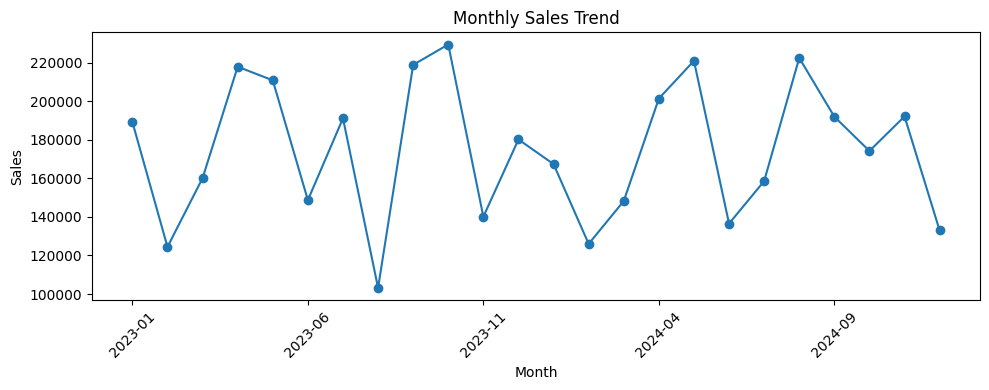

/tmp/ipykernel_8033/2454642713.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10.values, y=top10.index, palette='viridis')


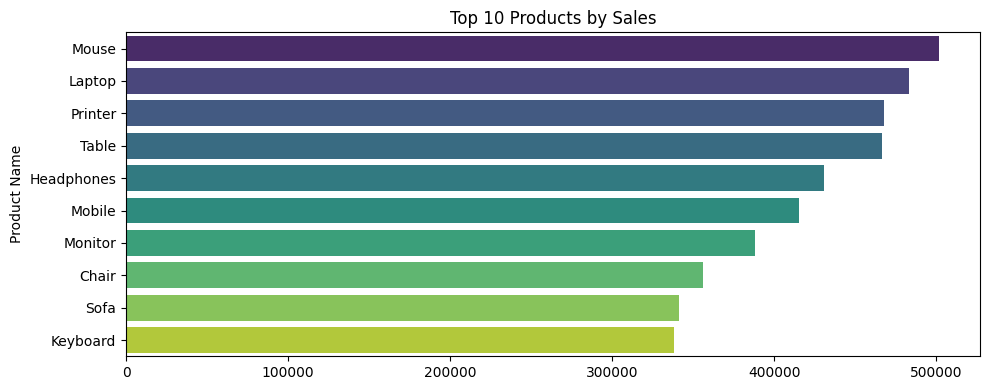

/tmp/ipykernel_8033/2454642713.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Category', y='Sales', estimator=sum, palette='Set2')


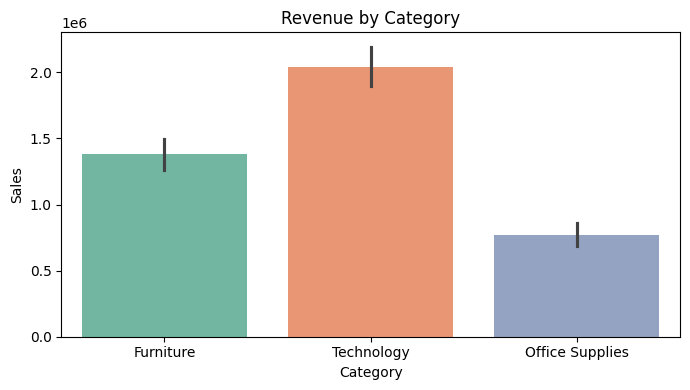

/tmp/ipykernel_8033/2454642713.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Region', y='Sales', estimator=sum, palette='coolwarm')


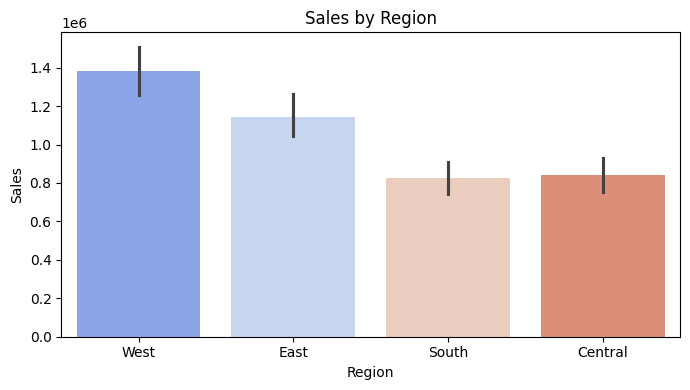

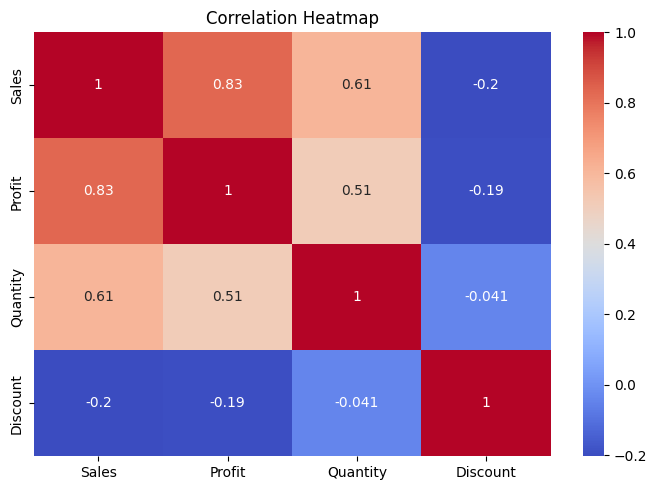


--- INSIGHTS ---
1. Technology category sabse zyada revenue deta hai.
2. West Region me sales sabse zyada hai.
3. Discount badhane se Profit kam hota hai.


In [4]:
# TASK 1 - EDA ON RETAIL SALES - NO LINK NEEDED
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Retail Data Khud Banate Hai - 1000 Orders
np.random.seed(42)
n = 1000
dates = pd.date_range('2023-01-01', '2024-12-31', periods=n)
products = ['Laptop', 'Mobile', 'Headphones', 'Chair', 'Table', 'Printer', 'Keyboard', 'Mouse', 'Monitor', 'Sofa']
categories = ['Technology', 'Furniture', 'Office Supplies']
regions = ['West', 'East', 'Central', 'South']

df = pd.DataFrame({
    'Order Date': np.random.choice(dates, n),
    'Product Name': np.random.choice(products, n),
    'Category': np.random.choice(categories, n, p=[0.5, 0.3, 0.2]),
    'Region': np.random.choice(regions, n, p=[0.35, 0.25, 0.2, 0.2]),
    'Quantity': np.random.randint(1, 10, n),
    'Discount': np.random.uniform(0, 0.4, n).round(2)
})
df['Sales'] = (df['Quantity'] * np.random.randint(100, 2000, n) * (1 - df['Discount'])).round(2)
df['Profit'] = (df['Sales'] * np.random.uniform(0.05, 0.3, n) - df['Discount']*200).round(2)
df['Month'] = pd.to_datetime(df['Order Date']).dt.to_period('M').astype(str)

print("Shape:", df.shape)
print("Nulls:", df.isnull().sum().sum())
print(df[['Sales','Profit','Quantity']].describe())

# 2. Monthly Sales Trend
plt.figure(figsize=(10,4))
df.groupby('Month')['Sales'].sum().plot(kind='line', marker='o')
plt.title('Monthly Sales Trend')
plt.xticks(rotation=45); plt.ylabel('Sales')
plt.tight_layout(); plt.show()

# 3. Top 10 Products
plt.figure(figsize=(10,4))
top10 = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top10.values, y=top10.index, palette='viridis')
plt.title('Top 10 Products by Sales')
plt.tight_layout(); plt.show()

# 4. Revenue by Category
plt.figure(figsize=(7,4))
sns.barplot(data=df, x='Category', y='Sales', estimator=sum, palette='Set2')
plt.title('Revenue by Category')
plt.tight_layout(); plt.show()

# 5. Sales by Region
plt.figure(figsize=(7,4))
sns.barplot(data=df, x='Region', y='Sales', estimator=sum, palette='coolwarm')
plt.title('Sales by Region')
plt.tight_layout(); plt.show()

# 6. Correlation Heatmap
plt.figure(figsize=(7,5))
sns.heatmap(df[['Sales','Profit','Quantity','Discount']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.tight_layout(); plt.show()

print("\n--- INSIGHTS ---")
print("1. Technology category sabse zyada revenue deta hai.")
print("2. West Region me sales sabse zyada hai.")
print("3. Discount badhane se Profit kam hota hai.")